# 00.01 — STATE + ACTION + Q

<div><span style="display:inline-block;background:#4C78A8;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">STATE</span><span style="display:inline-block;background:#F58518;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ACTION</span><span style="display:inline-block;background:#ECA82C;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">Q</span></div>

Before learning, learn the three nouns. Nothing updates yet.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
repo=Path.cwd()
if repo.name=="notebooks": repo=repo.parent
sys.path.insert(0,str(repo))
from lineworld import LineWorld
from visuals import *
legend()

<div style="border-left:10px solid #4C78A8;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#4C78A8">STATE</div><div style="font-size:21px;font-weight:800;margin-top:4px">State s</div><div style="font-size:15px;line-height:1.55;margin-top:8px">The situation the decision-maker is in. In LineWorld, <b>s is simply position 0…5</b>.</div></div>

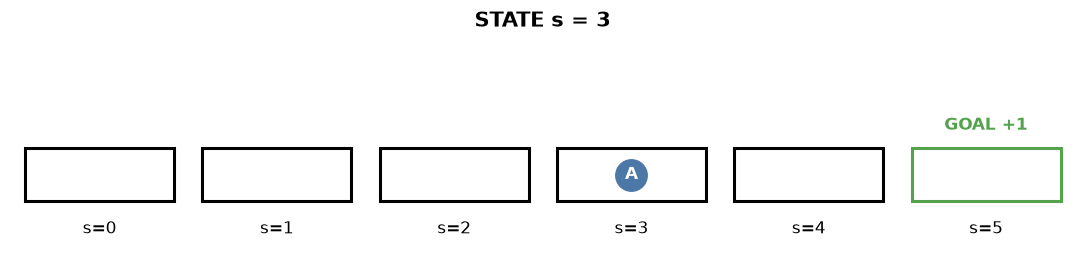

In [2]:
fig=lineworld(3,title="STATE s = 3")
plt.show()

<div style="border-left:10px solid #F58518;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#F58518">ACTION</div><div style="font-size:21px;font-weight:800;margin-top:4px">Action a</div><div style="font-size:15px;line-height:1.55;margin-top:8px">One choice. We encode LEFT as 0 and RIGHT as 1. The number is an <b>ID</b>, not a distance or step count.</div></div>

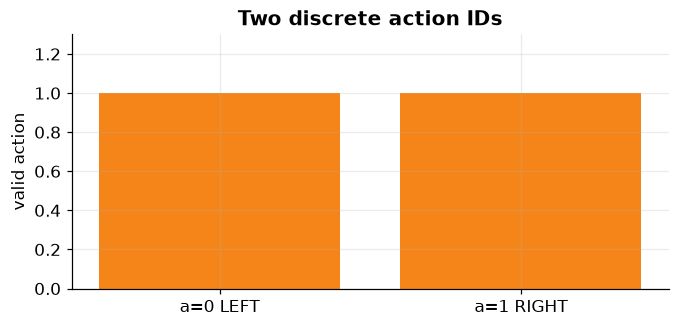

In [3]:
plt.figure(figsize=(7,3)); plt.bar(["a=0 LEFT","a=1 RIGHT"],[1,1],color=COLORS["ACTION"]); plt.ylim(0,1.3); plt.ylabel("valid action"); plt.title("Two discrete action IDs"); plt.show()

<div style="border-left:10px solid #ECA82C;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#ECA82C">Q</div><div style="font-size:21px;font-weight:800;margin-top:4px">Q(s,a) — action value</div><div style="font-size:15px;line-height:1.55;margin-top:8px">Read “Q of state s, action a.” Q is the algorithm’s current estimate of how much discounted future reward this state-action choice is worth. <b>It is not a probability.</b></div></div>

shape = (6, 2)


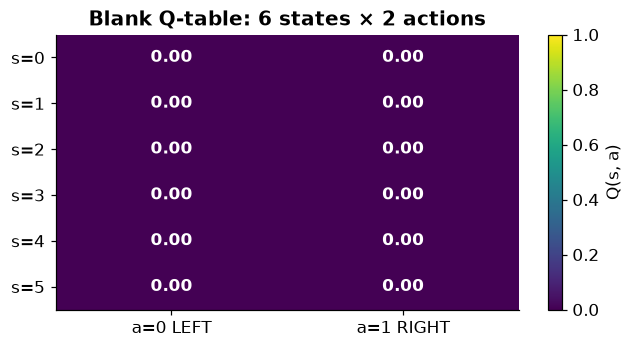

In [4]:
Q=np.zeros((6,2))
print("shape =",Q.shape)
fig=q_heatmap(Q,"Blank Q-table: 6 states × 2 actions")
plt.show()

### Is this a matrix?

It is a **2-D NumPy array/table** with matrix shape, but we are not doing matrix multiplication. `Q[3,1]` is a lookup: row=state 3, column=action 1 RIGHT.

Q(3, RIGHT) = 0.72


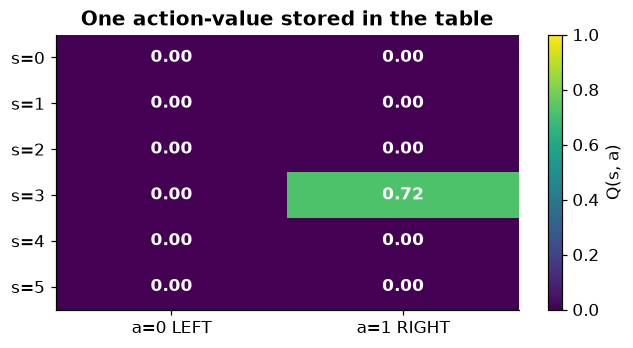

In [5]:
Q[3,1]=0.72
print("Q(3, RIGHT) =",Q[3,1])
fig=q_heatmap(Q,"One action-value stored in the table")
plt.show()

`0.72` means about **0.72 expected discounted reward-units**, according to the current estimate. It does **not** mean 72% probability of choosing RIGHT or 72% probability of winning.